<a href="https://colab.research.google.com/github/deekshitha29082006/WPT/blob/main/mini%20project2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [41]:

# INDIAN CURRENCY NOTE RECOGNITION USING CNN
# Complete Google Colab code: upload dataset, train, and predict

!pip install -q tensorflow

import os
import zipfile
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from google.colab import files
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing import image

# --------------------------------------------------
# 1. UPLOAD YOUR DATASET ZIP FILE
# --------------------------------------------------
# ZIP structure must be:
# dataset/
#   10/    (images of ₹10 notes)
#   20/    (images of ₹20 notes)
#   50/    (images of ₹50 notes)
#   100/   (images of ₹100 notes)
#   200/   (images of ₹200 notes)
#   500/   (images of ₹500 notes)

print("Upload a ZIP file containing your currency image folders.")
uploaded = files.upload()

zip_files = [f for f in uploaded if f.lower().endswith(".zip")]

if not zip_files:
    raise ValueError("Please upload a ZIP file containing the dataset folders.")

with zipfile.ZipFile(zip_files[0], "r") as zip_ref:
    zip_ref.extractall("/content")

# Find the dataset folder
DATA_DIR = "/content/dataset"

if not os.path.isdir(DATA_DIR):
    raise FileNotFoundError(
        "The ZIP must contain a folder named 'dataset' "
        "with denomination folders inside it."
    )

# Keep only denomination folders containing images
valid_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
class_names = sorted([
    folder for folder in os.listdir(DATA_DIR)
    if os.path.isdir(os.path.join(DATA_DIR, folder))
    and any(
        file.lower().endswith(valid_extensions)
        for file in os.listdir(os.path.join(DATA_DIR, folder))
    )
])

if len(class_names) < 2:
    raise ValueError(
        "At least two denomination folders with images are required."
    )

for name in class_names:
    count = sum(
        f.lower().endswith(valid_extensions)
        for f in os.listdir(os.path.join(DATA_DIR, name))
    )
    print(f"₹{name}: {count} images")

print("\nClasses:", class_names)

# --------------------------------------------------
# 2. LOAD AND PREPROCESS IMAGES
# --------------------------------------------------

IMG_SIZE = (128, 128)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    class_names=class_names
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    class_names=class_names
)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)

# --------------------------------------------------
# 3. BUILD CNN MODEL
# --------------------------------------------------

model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),
    layers.Rescaling(1.0 / 255),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(len(class_names), activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# --------------------------------------------------
# 4. TRAIN THE MODEL
# --------------------------------------------------

print("\nTraining CNN model...")

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

# Save trained model and labels
model.save("/content/currency_cnn_model.keras")

with open("/content/class_names.txt", "w") as f:
    f.write("\n".join(class_names))

print("\nModel training completed!")
print("Model saved successfully.")

# --------------------------------------------------
# 5. DISPLAY TRAINING ACCURACY
# --------------------------------------------------

plt.figure(figsize=(8, 4))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Currency Recognition Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# --------------------------------------------------
# 6. UPLOAD A CURRENCY IMAGE FOR PREDICTION
# --------------------------------------------------

print("\nUpload one currency note image to test the model.")
test_upload = files.upload()

test_images = [
    f for f in test_upload
    if f.lower().endswith(valid_extensions)
]

if not test_images:
    raise ValueError("Please upload a JPG, JPEG, PNG, BMP, or WEBP image.")

test_path = test_images[0]

img = image.load_img(test_path, target_size=IMG_SIZE)
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

predictions = model.predict(img_array, verbose=0)[0]
best_index = int(np.argmax(predictions))
predicted_label = class_names[best_index]
confidence = float(predictions[best_index]) * 100

# Display uploaded image and result
plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.axis("off")
plt.title(
    f"Predicted denomination: ₹{predicted_label}\n"
    f"Model confidence: {confidence:.2f}%"
)
plt.show()

print("===================================")
print(" INDIAN CURRENCY RECOGNITION RESULT")
print("===================================")
print(f"Predicted Note : ₹{predicted_label}")
print(f"Confidence     : {confidence:.2f}%")
print("===================================")

print("\nPrediction scores:")
for name, score in zip(class_names, predictions):
    print(f"₹{name}: {score * 100:.2f}%")

# Download the trained model
files.download("/content/currency_cnn_model.keras")


Upload a ZIP file containing your currency image folders.


KeyboardInterrupt: 


Upload images of ₹10 notes


Saving 10 to 10 (3)
Saved 12 images for ₹10

Upload images of ₹20 notes


Saving 20 to 20 (3)
Saved 12 images for ₹20

Upload images of ₹50 notes


Saving 50 to 50 (3)
Saved 0 images for ₹50

Upload images of ₹100 notes


Saving 100 to 100 (3)
Saved 0 images for ₹100

Upload images of ₹200 notes


...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_5 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,027 (12.61 MB)

 Trainable params: 3,305,027 (12.61 MB)

 Non-trainable params: 0 (0.00 B)


Training CNN model...
Epoch 1/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 486ms/step - accuracy: 0.4348 - loss: 1.0168 - val_accuracy: 0.4000 - val_loss: 1.1034
Epoch 2/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 291ms/step - accuracy: 0.4783 - loss: 0.9059 - val_accuracy: 0.4000 - val_loss: 1.0811
Epoch 3/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 329ms/step - accuracy: 0.6087 - loss: 0.8858 - val_accuracy: 0.4000 - val_loss: 1.0289
Epoch 4/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 387ms/step - accuracy: 0.6087 - loss: 0.8416 - val_accuracy: 0.6000 - val_loss: 0.9321
Epoch 5/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 463ms/step - accuracy: 0.5652 - loss: 0.7569 - val_accuracy: 0.6000 - val_loss: 0.8160
Epoch 6/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 453ms/step - accuracy: 0.6087 - loss: 1.3307 - val_accuracy: 0.6000 - val_loss: 0.7421
Epoch 7/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 340ms/step - accuracy: 0.6087 - loss: 0.6457 - val_accuracy: 0.6000 - val_loss: 0.7005
Epoch 8/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 301ms/step - accuracy: 0.5652 - loss: 0.6017 - val_accur

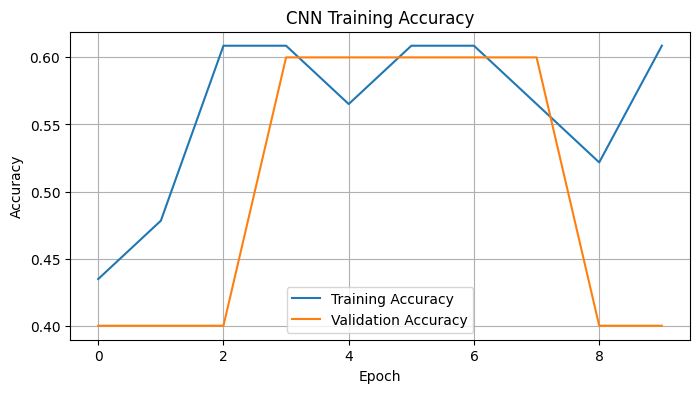


Upload a new currency note image


Saving 2000.jpg to 2000.jpg


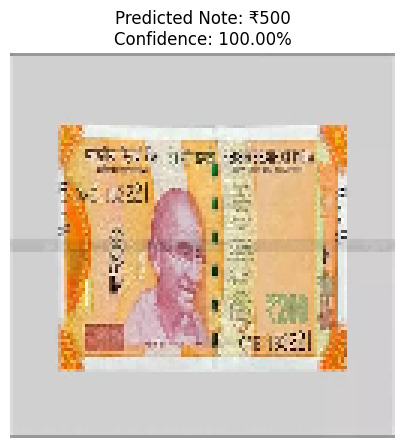

 INDIAN CURRENCY RECOGNITION RESULT
Predicted denomination: ₹500
Confidence: 100.00%

Prediction scores:
₹10: 0.00%
₹20: 0.00%
₹500: 100.00%


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [45]:

# INDIAN CURRENCY NOTE RECOGNITION USING CNN
# Google Colab - Complete Combined Code

!pip install -q tensorflow

import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from google.colab import files
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing import image

# 1. CREATE DATASET FOLDERS
DATA_DIR = "/content/dataset"
DENOMINATIONS = ["10", "20", "50", "100", "200", "500"]
EXTENSIONS = (".jpg", ".jpeg", ".png")

for denomination in DENOMINATIONS:
    os.makedirs(os.path.join(DATA_DIR, denomination), exist_ok=True)

# 2. UPLOAD CURRENCY IMAGES DIRECTLY
for denomination in DENOMINATIONS:
    print(f"\nUpload images of ₹{denomination} notes")
    uploaded = files.upload()

    for filename, content in uploaded.items():
        if filename.lower().endswith(EXTENSIONS):
            path = os.path.join(DATA_DIR, denomination, filename)
            with open(path, "wb") as f:
                f.write(content)

    count = sum(
        f.lower().endswith(EXTENSIONS)
        for f in os.listdir(os.path.join(DATA_DIR, denomination))
    )
    print(f"Saved {count} images for ₹{denomination}")

# 3. CHECK DATASET
class_names = [
    d for d in DENOMINATIONS
    if any(
        f.lower().endswith(EXTENSIONS)
        for f in os.listdir(os.path.join(DATA_DIR, d))
    )
]

if len(class_names) < 2:
    raise ValueError(
        "Upload images for at least two denominations to train the CNN."
    )

for name in class_names:
    count = sum(
        f.lower().endswith(EXTENSIONS)
        for f in os.listdir(os.path.join(DATA_DIR, name))
    )
    print(f"₹{name}: {count} images")

# 4. LOAD AND PREPROCESS IMAGES
IMG_SIZE = (128, 128)
BATCH_SIZE = 16

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_names=class_names
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_names=class_names
)

# 5. BUILD CNN MODEL
model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),
    layers.Rescaling(1.0 / 255),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(len(class_names), activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# 6. TRAIN CNN MODEL
print("\nTraining CNN model...")

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

# 7. SAVE MODEL AND CLASS NAMES
model.save("/content/currency_cnn_model.keras")

with open("/content/class_names.txt", "w") as f:
    f.write("\n".join(class_names))

print("\nCNN model training completed!")

# 8. DISPLAY ACCURACY GRAPH
plt.figure(figsize=(8, 4))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# 9. UPLOAD A NEW IMAGE FOR PREDICTION
print("\nUpload a new currency note image")
test_upload = files.upload()

test_files = [
    f for f in test_upload
    if f.lower().endswith(EXTENSIONS)
]

if not test_files:
    raise ValueError("Upload a JPEG, JPG, or PNG image.")

test_path = test_files[0]

img = image.load_img(test_path, target_size=IMG_SIZE)
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

predictions = model.predict(img_array, verbose=0)[0]
index = int(np.argmax(predictions))

# 10. DISPLAY PREDICTION RESULT
plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.axis("off")
plt.title(
    f"Predicted Note: ₹{class_names[index]}\n"
    f"Confidence: {predictions[index] * 100:.2f}%"
)
plt.show()

print("======================================")
print(" INDIAN CURRENCY RECOGNITION RESULT")
print("======================================")
print(f"Predicted denomination: ₹{class_names[index]}")
print(f"Confidence: {predictions[index] * 100:.2f}%")
print("======================================")

print("\nPrediction scores:")
for name, score in zip(class_names, predictions):
    print(f"₹{name}: {score * 100:.2f}%")

# 11. DOWNLOAD THE TRAINED MODEL
files.download("/content/currency_cnn_model.keras")



Upload JPEG/JPG/PNG images of ₹10 notes


Saving 10 to 10 (4)
₹10: 12 images saved

Upload JPEG/JPG/PNG images of ₹20 notes


Saving 20 to 20 (4)
₹20: 12 images saved

Upload JPEG/JPG/PNG images of ₹50 notes


Saving 50 to 50 (4)
₹50: 0 images saved

Upload JPEG/JPG/PNG images of ₹100 notes


Saving 100 to 100 (4)
₹100: 0 images saved

Upload JPEG/JPG/PNG images of ₹200 notes


...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_6 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_18 (MaxPooling2D) │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_19 (MaxPooling2D) │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_20 (Conv2D)              │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_20 (MaxPooling2D) │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,027 (12.61 MB)

 Trainable params: 3,305,027 (12.61 MB)

 Non-trainable params: 0 (0.00 B)


Training CNN model...
Epoch 1/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 512ms/step - accuracy: 0.3750 - loss: 1.0511 - val_accuracy: 0.4000 - val_loss: 1.1031
Epoch 2/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 329ms/step - accuracy: 0.6250 - loss: 0.8700 - val_accuracy: 0.4000 - val_loss: 1.0902
Epoch 3/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 328ms/step - accuracy: 0.6250 - loss: 0.8603 - val_accuracy: 0.4000 - val_loss: 1.0723
Epoch 4/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 342ms/step - accuracy: 0.6250 - loss: 0.8351 - val_accuracy: 0.4000 - val_loss: 1.0279
Epoch 5/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 338ms/step - accuracy: 0.6667 - loss: 0.7930 - val_accuracy: 0.4000 - val_loss: 0.9653
Epoch 6/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 621ms/step - accuracy: 0.6250 - loss: 0.7266 - val_accuracy: 0.4000 - val_loss: 0.8896
Epoch 7/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 1s/step - accuracy: 0.6667 - loss: 0.6694 - val_accuracy: 0.4000 - val_loss: 0.8287
Epoch 8/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 340ms/step - accuracy: 0.6667 - loss: 0.6167 - val_accuracy

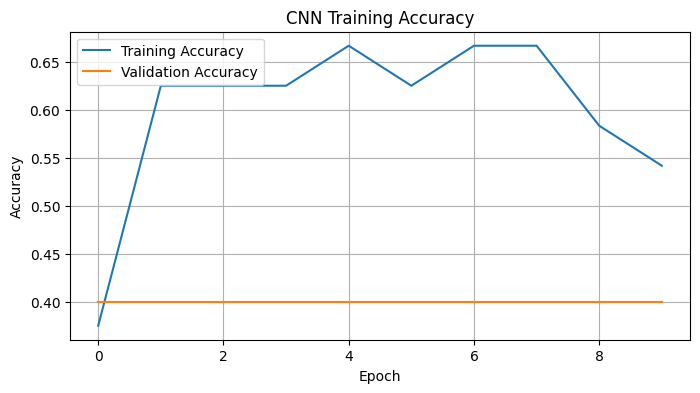


Upload one new currency note image for prediction


Saving 2000.jpg to 2000 (1).jpg


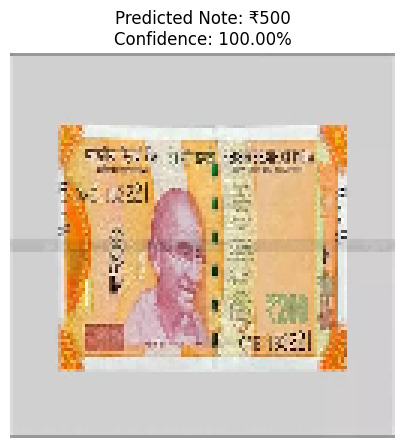

 INDIAN CURRENCY RECOGNITION RESULT
Predicted denomination: ₹500
Confidence: 100.00%

Prediction scores:
₹10: 0.00%
₹20: 0.00%
₹500: 100.00%

Application Link:


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [46]:
# INDIAN CURRENCY NOTE RECOGNITION USING CNN
# Complete Google Colab Code with Link-Type Output

!pip install -q tensorflow

import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from google.colab import files
from IPython.display import display, HTML
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing import image

# 1. CREATE DATASET FOLDERS
DATA_DIR = "/content/dataset"
DENOMINATIONS = ["10", "20", "50", "100", "200", "500"]
EXTENSIONS = (".jpg", ".jpeg", ".png")

for denomination in DENOMINATIONS:
    os.makedirs(os.path.join(DATA_DIR, denomination), exist_ok=True)

# 2. UPLOAD CURRENCY NOTE IMAGES
for denomination in DENOMINATIONS:
    print(f"\nUpload JPEG/JPG/PNG images of ₹{denomination} notes")
    uploaded = files.upload()

    for filename, content in uploaded.items():
        if filename.lower().endswith(EXTENSIONS):
            save_path = os.path.join(
                DATA_DIR, denomination, filename
            )
            with open(save_path, "wb") as f:
                f.write(content)

    count = sum(
        f.lower().endswith(EXTENSIONS)
        for f in os.listdir(os.path.join(DATA_DIR, denomination))
    )
    print(f"₹{denomination}: {count} images saved")

# 3. CHECK DATASET
class_names = [
    d for d in DENOMINATIONS
    if any(
        f.lower().endswith(EXTENSIONS)
        for f in os.listdir(os.path.join(DATA_DIR, d))
    )
]

if len(class_names) < 2:
    raise ValueError(
        "Upload images for at least two denominations."
    )

for name in class_names:
    count = sum(
        f.lower().endswith(EXTENSIONS)
        for f in os.listdir(os.path.join(DATA_DIR, name))
    )
    print(f"₹{name}: {count} images")

# 4. LOAD AND PREPROCESS DATASET
IMG_SIZE = (128, 128)
BATCH_SIZE = 16

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_names=class_names
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_names=class_names
)

# 5. BUILD CNN MODEL
model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),
    layers.Rescaling(1.0 / 255),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(len(class_names), activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# 6. TRAIN CNN MODEL
print("\nTraining CNN model...")

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

# 7. SAVE MODEL AND LABELS
model.save("/content/currency_cnn_model.keras")

with open("/content/class_names.txt", "w") as f:
    f.write("\n".join(class_names))

print("\nCNN model training completed!")

# 8. DISPLAY ACCURACY GRAPH
plt.figure(figsize=(8, 4))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# 9. UPLOAD NEW CURRENCY IMAGE
print("\nUpload one new currency note image for prediction")
test_upload = files.upload()

test_files = [
    f for f in test_upload
    if f.lower().endswith(EXTENSIONS)
]

if not test_files:
    raise ValueError("Upload a JPEG, JPG, or PNG image.")

test_path = test_files[0]

img = image.load_img(test_path, target_size=IMG_SIZE)
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

# 10. PREDICT DENOMINATION
predictions = model.predict(img_array, verbose=0)[0]
index = int(np.argmax(predictions))

plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.axis("off")
plt.title(
    f"Predicted Note: ₹{class_names[index]}\n"
    f"Confidence: {predictions[index] * 100:.2f}%"
)
plt.show()

print("======================================")
print(" INDIAN CURRENCY RECOGNITION RESULT")
print("======================================")
print(f"Predicted denomination: ₹{class_names[index]}")
print(f"Confidence: {predictions[index] * 100:.2f}%")
print("======================================")

print("\nPrediction scores:")
for name, score in zip(class_names, predictions):
    print(f"₹{name}: {score * 100:.2f}%")

# 11. CREATE CLICKABLE LINK OUTPUT
print("\nApplication Link:")

display(HTML("""
<div style="border:1px solid #cccccc; padding:18px;
            border-radius:10px; font-family:Arial;">
    <h3>Indian Currency Note Recognition Using CNN</h3>
    <p>Click below to open Google Colab.</p>
    <a href="https://colab.research.google.com/"
       target="_blank"
       style="display:inline-block; padding:10px 16px;
              background:#1967d2; color:white;
              text-decoration:none; border-radius:6px;">
       Open Currency Recognition Project
    </a>
</div>
"""))

# 12. DOWNLOAD TRAINED MODEL
files.download("/content/currency_cnn_model.keras")



Upload JPEG/JPG/PNG images of ₹10 notes


Saving 10 to 10 (5)
₹10: 12 images saved

Upload JPEG/JPG/PNG images of ₹20 notes


Saving 20 to 20 (5)
₹20: 12 images saved

Upload JPEG/JPG/PNG images of ₹50 notes


Saving 50 to 50 (5)
₹50: 0 images saved

Upload JPEG/JPG/PNG images of ₹100 notes


Saving 100 to 100 (5)
₹100: 0 images saved

Upload JPEG/JPG/PNG images of ₹200 notes


...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_7 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_21 (Conv2D)              │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_21 (MaxPooling2D) │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_22 (Conv2D)              │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_22 (MaxPooling2D) │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_23 (Conv2D)              │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_23 (MaxPooling2D) │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_7 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,027 (12.61 MB)

 Trainable params: 3,305,027 (12.61 MB)

 Non-trainable params: 0 (0.00 B)


Training CNN model...
Epoch 1/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 4s 493ms/step - accuracy: 0.5833 - loss: 0.9535 - val_accuracy: 0.5000 - val_loss: 1.1030
Epoch 2/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 339ms/step - accuracy: 0.5000 - loss: 0.8256 - val_accuracy: 0.5000 - val_loss: 1.0849
Epoch 3/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 352ms/step - accuracy: 0.6250 - loss: 0.8101 - val_accuracy: 0.5000 - val_loss: 1.0505
Epoch 4/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 305ms/step - accuracy: 0.5000 - loss: 0.8662 - val_accuracy: 0.5000 - val_loss: 1.0138
Epoch 5/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 320ms/step - accuracy: 0.6250 - loss: 0.7690 - val_accuracy: 0.5000 - val_loss: 0.9843
Epoch 6/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 306ms/step - accuracy: 0.5833 - loss: 0.7332 - val_accuracy: 0.5000 - val_loss: 0.9388
Epoch 7/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 345ms/step - accuracy: 0.5833 - loss: 0.6933 - val_accuracy: 0.5000 - val_loss: 0.8843
Epoch 8/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 353ms/step - accuracy: 0.5833 - loss: 0.6636 - val_accur

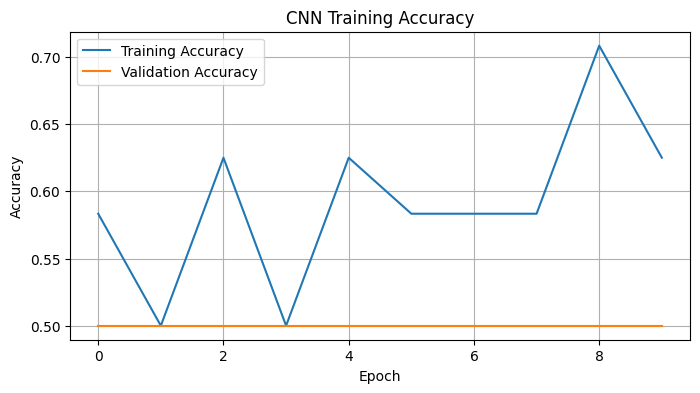


Upload one new currency note image for prediction


Saving 5005.jpg to 5005.jpg


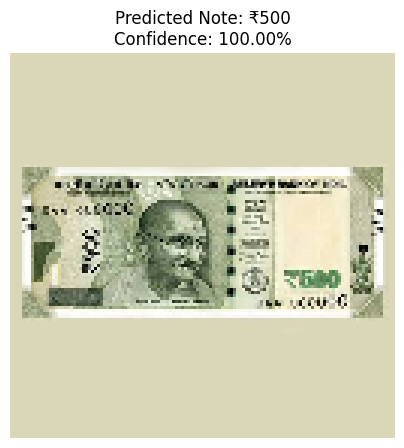

 INDIAN CURRENCY RECOGNITION RESULT
Predicted denomination: ₹500
Confidence: 100.00%

Prediction scores:
₹10: 0.00%
₹20: 0.00%
₹500: 100.00%

Application Link:


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [49]:

# INDIAN CURRENCY NOTE RECOGNITION USING CNN
# Complete Google Colab Code with Link-Type Output

!pip install -q tensorflow

import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from google.colab import files
from IPython.display import display, HTML
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing import image

# 1. CREATE DATASET FOLDERS
DATA_DIR = "/content/dataset"
DENOMINATIONS = ["10", "20", "50", "100", "200", "500"]
EXTENSIONS = (".jpg", ".jpeg", ".png")

for denomination in DENOMINATIONS:
    os.makedirs(os.path.join(DATA_DIR, denomination), exist_ok=True)

# 2. UPLOAD CURRENCY NOTE IMAGES
for denomination in DENOMINATIONS:
    print(f"\nUpload JPEG/JPG/PNG images of ₹{denomination} notes")
    uploaded = files.upload()

    for filename, content in uploaded.items():
        if filename.lower().endswith(EXTENSIONS):
            save_path = os.path.join(
                DATA_DIR, denomination, filename
            )
            with open(save_path, "wb") as f:
                f.write(content)

    count = sum(
        f.lower().endswith(EXTENSIONS)
        for f in os.listdir(os.path.join(DATA_DIR, denomination))
    )
    print(f"₹{denomination}: {count} images saved")

# 3. CHECK DATASET
class_names = [
    d for d in DENOMINATIONS
    if any(
        f.lower().endswith(EXTENSIONS)
        for f in os.listdir(os.path.join(DATA_DIR, d))
    )
]

if len(class_names) < 2:
    raise ValueError(
        "Upload images for at least two denominations."
    )

for name in class_names:
    count = sum(
        f.lower().endswith(EXTENSIONS)
        for f in os.listdir(os.path.join(DATA_DIR, name))
    )
    print(f"₹{name}: {count} images")

# 4. LOAD AND PREPROCESS DATASET
IMG_SIZE = (128, 128)
BATCH_SIZE = 16

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_names=class_names
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_names=class_names
)

# 5. BUILD CNN MODEL
model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),
    layers.Rescaling(1.0 / 255),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(len(class_names), activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# 6. TRAIN CNN MODEL
print("\nTraining CNN model...")

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

# 7. SAVE MODEL AND LABELS
model.save("/content/currency_cnn_model.keras")

with open("/content/class_names.txt", "w") as f:
    f.write("\n".join(class_names))

print("\nCNN model training completed!")

# 8. DISPLAY ACCURACY GRAPH
plt.figure(figsize=(8, 4))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# 9. UPLOAD NEW CURRENCY IMAGE
print("\nUpload one new currency note image for prediction")
test_upload = files.upload()

test_files = [
    f for f in test_upload
    if f.lower().endswith(EXTENSIONS)
]

if not test_files:
    raise ValueError("Upload a JPEG, JPG, or PNG image.")

test_path = test_files[0]

img = image.load_img(test_path, target_size=IMG_SIZE)
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

# 10. PREDICT DENOMINATION
predictions = model.predict(img_array, verbose=0)[0]
index = int(np.argmax(predictions))

plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.axis("off")
plt.title(
    f"Predicted Note: ₹{class_names[index]}\n"
    f"Confidence: {predictions[index] * 100:.2f}%"
)
plt.show()

print("======================================")
print(" INDIAN CURRENCY RECOGNITION RESULT")
print("======================================")
print(f"Predicted denomination: ₹{class_names[index]}")
print(f"Confidence: {predictions[index] * 100:.2f}%")
print("======================================")

print("\nPrediction scores:")
for name, score in zip(class_names, predictions):
    print(f"₹{name}: {score * 100:.2f}%")

# 11. CREATE CLICKABLE LINK OUTPUT
print("\nApplication Link:")

display(HTML("""
<div style="border:1px solid #cccccc; padding:18px;
            border-radius:10px; font-family:Arial;">
    <h3>Indian Currency Note Recognition Using CNN</h3>
    <p>Click below to open Google Colab.</p>
    <a href="https://colab.research.google.com/"
       target="_blank"
       style="display:inline-block; padding:10px 16px;
              background:#1967d2; color:white;
              text-decoration:none; border-radius:6px;">
       Open Currency Recognition Project
    </a>
</div>
"""))

# 12. DOWNLOAD TRAINED MODEL
files.download("/content/currency_cnn_model.keras")


Upload images of Apple phones


Saving apple to apple (1)
Saving apple 11 to apple 11 (2)
Saving apple2 to apple2
Apple: 4 images saved

Upload images of Samsung phones


Saving samsung to samsung (2)
Saving samsung1 to samsung1 (1)
Saving samsung2 to samsung2 (2)
Samsung: 4 images saved

Upload images of Xiaomi phones


Saving xiamoi.jpg to xiamoi.jpg
Saving xiamoi 17 to xiamoi 17 (2)
Saving xiamoi 1.jpg to xiamoi 1.jpg
Saving xiamoi 3 to xiamoi 3 (2)
Xiaomi: 5 images saved

Upload images of OnePlus phones


Saving oneplus to oneplus (2)
Saving oneplus1 to oneplus1 (2)
OnePlus: 3 images saved

Upload images of Vivo phones


...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_8 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_24 (Conv2D)              │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_24 (MaxPooling2D) │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_25 (Conv2D)              │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_25 (MaxPooling2D) │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_26 (Conv2D)              │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_26 (MaxPooling2D) │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,018 (429.76 KB)

 Trainable params: 110,018 (429.76 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - accuracy: 0.4167 - loss: 0.6973 - val_accuracy: 0.6667 - val_loss: 0.6219
Epoch 2/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 496ms/step - accuracy: 0.6667 - loss: 0.6514 - val_accuracy: 0.6667 - val_loss: 0.5887
Epoch 3/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 415ms/step - accuracy: 0.6667 - loss: 0.6134 - val_accuracy: 0.6667 - val_loss: 0.5654
Epoch 4/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 440ms/step - accuracy: 0.6667 - loss: 0.6632 - val_accuracy: 0.6667 - val_loss: 0.5615
Epoch 5/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 630ms/step - accuracy: 0.6667 - loss: 0.6413 - val_accuracy: 0.6667 - val_loss: 0.5628
Epoch 6/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 455ms/step - accuracy: 0.6667 - loss: 0.5876 - val_accuracy: 0.6667 - val_loss: 0.5679
Epoch 7/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 564ms/step - accuracy: 0.6667 - loss: 0.5747 - val_accuracy: 0.6667 - val_loss: 0.5744
Epoch 8/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 646ms/step - accuracy: 0.6667 - loss: 0.5498 - val_accuracy: 0.6667 - val_loss: 0.

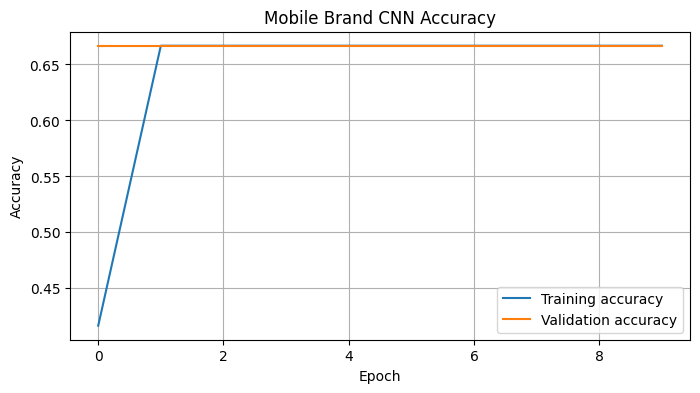

Creating public application link...

APPLICATION READY!
Open this URL: https://perspective-brisbane-claire-jewel.trycloudflare.com



Keep this Colab session running while using the app.
Code setup complete.


In [57]:

# MOBILE PHONE BRAND CLASSIFICATION USING CNN
# Complete Google Colab Application

!pip install -q tensorflow streamlit pillow

import os
import sys
import time
import subprocess
import re
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from google.colab import files
from IPython.display import display, HTML
from tensorflow.keras import layers, models

# ------------------------------------------------
# 1. CREATE DATASET FOLDERS
# ------------------------------------------------

DATA_DIR = "/content/mobile_dataset"
BRANDS = ["Apple", "Samsung", "Xiaomi", "OnePlus", "Vivo"]
EXTENSIONS = (".jpg", ".jpeg", ".png")
IMG_SIZE = (128, 128)
BATCH_SIZE = 16

for brand in BRANDS:
    os.makedirs(os.path.join(DATA_DIR, brand), exist_ok=True)

# ------------------------------------------------
# 2. UPLOAD PHONE IMAGES DIRECTLY
# ------------------------------------------------

for brand in BRANDS:
    print(f"\nUpload images of {brand} phones")
    uploaded = files.upload()

    for filename, content in uploaded.items():
        if filename.lower().endswith(EXTENSIONS):
            save_path = os.path.join(DATA_DIR, brand, filename)
            with open(save_path, "wb") as f:
                f.write(content)

    count = sum(
        f.lower().endswith(EXTENSIONS)
        for f in os.listdir(os.path.join(DATA_DIR, brand))
    )
    print(f"{brand}: {count} images saved")

# ------------------------------------------------
# 3. CHECK DATASET
# ------------------------------------------------

class_names = [
    brand for brand in BRANDS
    if sum(
        f.lower().endswith(EXTENSIONS)
        for f in os.listdir(os.path.join(DATA_DIR, brand))
    ) >= 5
]

if len(class_names) < 2:
    raise ValueError(
        "Upload at least 5 images for each of at least 2 brands."
    )

for brand in class_names:
    print(
        brand,
        "images:",
        len([
            f for f in os.listdir(os.path.join(DATA_DIR, brand))
            if f.lower().endswith(EXTENSIONS)
        ])
    )

# ------------------------------------------------
# 4. LOAD AND PREPROCESS IMAGES
# ------------------------------------------------

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_names=class_names
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_names=class_names
)

# ------------------------------------------------
# 5. BUILD CNN MODEL
# ------------------------------------------------

model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),
    layers.Rescaling(1.0 / 255),

    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(len(class_names), activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# ------------------------------------------------
# 6. TRAIN MODEL
# ------------------------------------------------

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

MODEL_PATH = "/content/mobile_brand_model.keras"
LABEL_PATH = "/content/brand_names.txt"

model.save(MODEL_PATH)

with open(LABEL_PATH, "w") as f:
    f.write("\n".join(class_names))

print("\nCNN model training completed!")

# ------------------------------------------------
# 7. DISPLAY TRAINING ACCURACY
# ------------------------------------------------

plt.figure(figsize=(8, 4))
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.title("Mobile Brand CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# ------------------------------------------------
# 8. CREATE STREAMLIT APPLICATION
# ------------------------------------------------

app_code = r'''
import streamlit as st
import tensorflow as tf
import numpy as np
from PIL import Image

st.set_page_config(
    page_title="Mobile Brand AI",
    page_icon="📱",
    layout="centered"
)

@st.cache_resource
def load_model():
    model = tf.keras.models.load_model(
        "/content/mobile_brand_model.keras"
    )
    with open("/content/brand_names.txt", "r") as f:
        brands = f.read().splitlines()
    return model, brands

st.title("📱 Mobile Phone Brand Classification")
st.caption("CNN-powered image recognition application")

st.write(
    "Upload a clear photo of a mobile phone to predict its brand."
)

model, brands = load_model()

uploaded = st.file_uploader(
    "Choose a mobile phone image",
    type=["jpg", "jpeg", "png"]
)

if uploaded:
    img = Image.open(uploaded).convert("RGB")
    st.image(img, caption="Uploaded phone image",
             use_container_width=True)

    if st.button("Identify Phone Brand", type="primary"):
        resized = img.resize((128, 128))
        array = np.array(resized, dtype=np.float32)
        array = np.expand_dims(array, axis=0)

        scores = model.predict(array, verbose=0)[0]
        best = int(np.argmax(scores))

        st.success(f"Predicted Brand: {brands[best]}")
        st.metric("Model confidence", f"{scores[best] * 100:.2f}%")

        st.subheader("Brand prediction scores")
        for brand, score in sorted(
            zip(brands, scores), key=lambda item: item[1],
            reverse=True
        ):
            st.write(f"{brand}: {score * 100:.2f}%")
            st.progress(float(score))

st.info(
    "This is an educational image classifier. Results depend on "
    "the quality and variety of the training images."
)
'''

with open("/content/app.py", "w") as f:
    f.write(app_code)

# ------------------------------------------------
# 9. START STREAMLIT
# ------------------------------------------------

server_log = open("/content/streamlit.log", "w")

server = subprocess.Popen(
    [
        sys.executable, "-m", "streamlit", "run",
        "/content/app.py",
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true"
    ],
    stdout=server_log,
    stderr=subprocess.STDOUT
)

time.sleep(8)

if server.poll() is not None:
    server_log.flush()
    print(open("/content/streamlit.log").read()[-3000:])
    raise RuntimeError("Streamlit could not start.")

# ------------------------------------------------
# 10. START CLOUDFLARE HTTPS TUNNEL
# ------------------------------------------------

print("Creating public application link...")

result = subprocess.run(
    [
        "wget", "-q",
        "https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64",
        "-O", "/content/cloudflared"
    ]
)

if result.returncode != 0:
    raise RuntimeError(
        "Could not download the tunnel tool. Check internet access."
    )

os.chmod("/content/cloudflared", 0o755)

tunnel_log = open("/content/tunnel.log", "w")

tunnel = subprocess.Popen(
    [
        "/content/cloudflared", "tunnel",
        "--url", "http://127.0.0.1:8501",
        "--no-autoupdate"
    ],
    stdout=tunnel_log,
    stderr=subprocess.STDOUT
)

public_url = None

for _ in range(60):
    time.sleep(1)
    tunnel_log.flush()

    with open("/content/tunnel.log", "r") as f:
        log_text = f.read()

    matches = re.findall(
        r"https://[a-zA-Z0-9-]+\.trycloudflare\.com",
        log_text
    )

    if matches:
        public_url = matches[-1]
        break

# ------------------------------------------------
# 11. DISPLAY REAL APPLICATION LINK
# ------------------------------------------------

if public_url:
    print("\nAPPLICATION READY!")
    print("Open this URL:", public_url)

    display(HTML(f"""
    <div style="padding:24px;border-radius:12px;
                border:1px solid #cbd5e1;font-family:Arial">
        <h2>📱 Mobile Phone Brand Classification</h2>
        <p>Your CNN application is running.</p>
        <a href="{public_url}" target="_blank"
           style="display:inline-block;background:#2563eb;
                  color:white;padding:12px 20px;
                  border-radius:8px;text-decoration:none">
           Open Mobile Brand App
        </a>
        <p><a href="{public_url}" target="_blank">{public_url}</a></p>
    </div>
    """))
else:
    print("Could not create the public link.")
    with open("/content/tunnel.log", "r") as f:
        print(f.read()[-3000:])

print("\nKeep this Colab session running while using the app.")
'''

print("Code setup complete.")
